# 04 - Dynamic Linear Model 

The regression coefficients are allowed to vary over time, cast as a **Dynamic
Linear Model (DLM)**. The latent state
$\theta_t$ collects the time-varying coefficients; this is a **dynamic
regression**, i.e. a DLM with $F_t = (1\;\; x_t^\top)$ and $G_t = I_p$
(random-walk / local-level evolution of the state).

$$
\begin{aligned}
\theta_0 &\sim N_p(m_0, C_0), \\
Y_t &= F_t\,\theta_t + v_t, & v_t &\sim N(0, V), \\
\theta_t &= G_t\,\theta_{t-1} + w_t, & w_t &\sim N_p(0, W).
\end{aligned}
$$

Here $Y_t$ is the excess return, $F_t = (1,\, \mathrm{SP500}_t,\, \mathrm{UST10Y}_t,\,
\mathrm{fxvol}_t,\, \mathrm{TED}_t,\, \mathrm{VIX}_t)$ is the row of regressors,
$\theta_t \in \mathbb{R}^p$ ($p=6$) the coefficient vector, and $G_t = I_p$.

**Specification choices.** $m_0$ and $C_0$ are the full-sample OLS estimate and
its covariance. The observation variance $V$ is estimated by maximum likelihood.
The evolution covariance is calibrated per coefficient,
$W = \lambda \cdot \operatorname{diag}\!\big(\widehat{\operatorname{Var}}(\hat\theta_{\text{OLS}})\big)$,
so weakly-identified coefficients do not diverge. $\lambda$ sets how far the
coefficients may travel: each one moves by $\sqrt{\lambda}$ OLS standard errors
per day, which over $n$ days adds up to a prior standard deviation of
$\sqrt{n\lambda}$ standard errors. With $\lambda = 10^{-3}$ and $n \approx 5{,}800$
that is about 2.4. Smaller $\lambda$ gives a smoother state. The value is fixed,
not estimated; notebook 05 shows what the likelihood says about it and how the
results change with it.

## Kalman filter

Given $\theta_{t-1}\mid y_{1:t-1} \sim N_p(m_{t-1}, C_{t-1})$, the recursions are

$$
\begin{aligned}
\textbf{prediction:} \quad & a_t = G_t\,m_{t-1}, & R_t &= G_t\,C_{t-1}\,G_t^\top + W, \\
\textbf{forecast:} \quad & f_t = F_t\,a_t, & Q_t &= F_t\,R_t\,F_t^\top + V, \\
\textbf{innovation:} \quad & e_t = Y_t - f_t, & K_t &= R_t\,F_t^\top\,Q_t^{-1}, \\
\textbf{update:} \quad & m_t = a_t + K_t\,e_t, & C_t &= R_t - K_t\,Q_t\,K_t^\top.
\end{aligned}
$$

Filtering gives $\theta_t \mid y_{1:t} \sim N_p(m_t, C_t)$; the backward Kalman
smoother gives $\theta_t \mid y_{1:T}$. Below, `statsmodels` runs exactly these
recursions internally; the plotted paths are the smoothed means
$\mathbb{E}(\theta_t \mid y_{1:T})$ with $\pm 2$ standard-deviation bands.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import safe_haven as sh
from safe_haven import CURRENCIES, REGRESSORS, TERMS, LAMBDA, DATA_DIR, FIG_DIR

## Load and construct variables

Same construction as notebooks 02-03, from the shared `safe_haven.py`.

In [2]:
data = sh.load_data()

## The DLM

State-space model with the time-varying coefficient vector $\theta_t$ as the
state. Matrix names follow the course: $F$ = design, $G$ = transition,
$V$ = observation covariance, $W$ = state covariance, $(m_0, C_0)$ = initial state. The class is defined in `safe_haven.py`.

In [3]:
def fit_dlm(cur):
    """Smoothed path, its standard errors, the constant OLS estimate, and the fit."""
    df = data.model_frame(cur)
    res, ols = sh.dlm_fit(df)
    theta = pd.DataFrame(res.smoothed_state.T, index=df.index, columns=TERMS)
    sd = pd.DataFrame(
        np.sqrt(np.diagonal(res.smoothed_state_cov, axis1=0, axis2=1)),
        index=df.index, columns=TERMS)
    return theta, sd, ols.params, res


dlm, fits = {}, {}
for cur in CURRENCIES:
    theta, sd, params, res = fit_dlm(cur)
    dlm[cur] = (theta, sd, params)
    fits[cur] = res

## Single coefficients across currencies

Smoothed path $\mathbb{E}(\theta_{t} \mid y_{1:T})$ with a $\pm 2$ SD band, the
full-sample OLS value (dashed grey), and the break dates from notebook 03 (dotted
red). First the S&P 500 coefficient, where most of the movement is, then the
fx-volatility coefficient, which hardly moves at all.

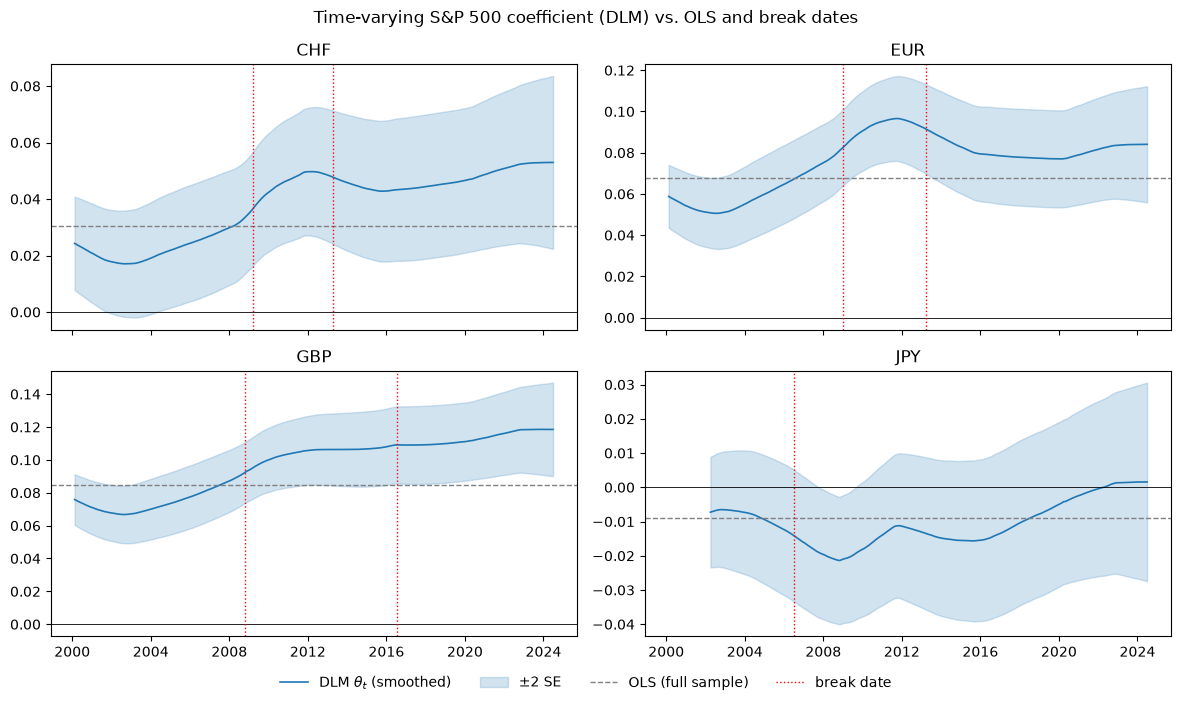

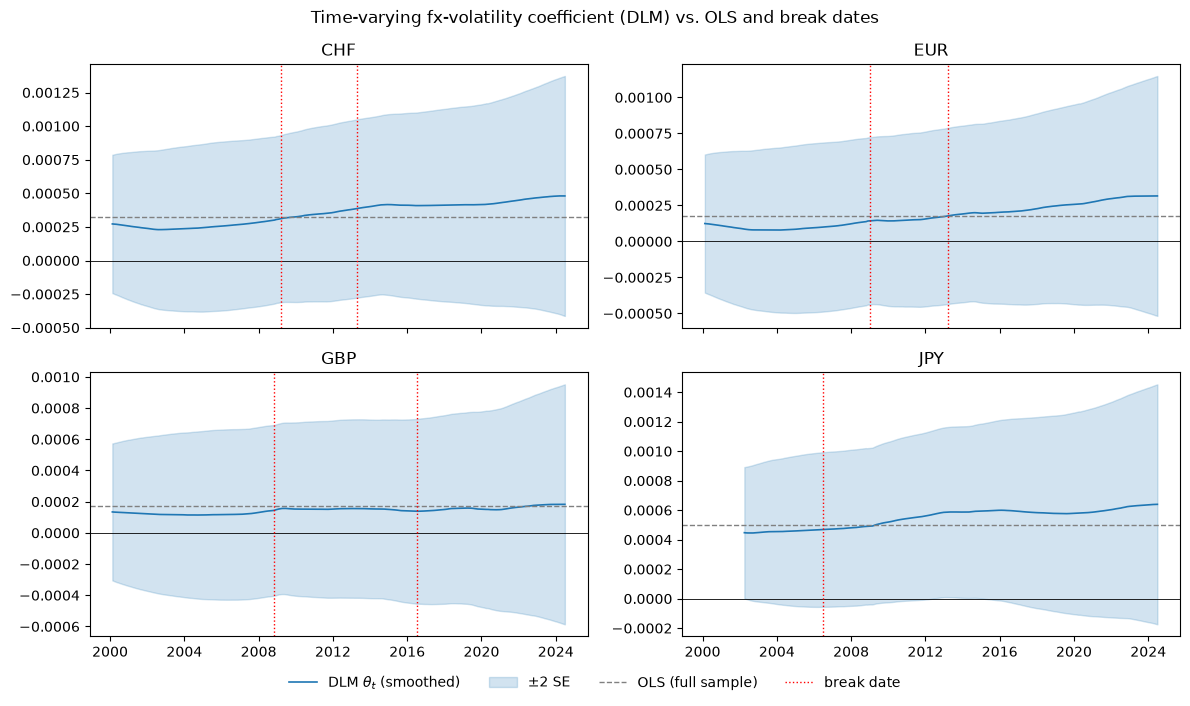

In [4]:
bp = sh.break_dates()
LABEL = {"SP500": "S&P 500", "fxvol": "fx-volatility"}

FIG_DIR.mkdir(exist_ok=True)
for COEF in ["SP500", "fxvol"]:
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    for ax, cur in zip(axes.ravel(), CURRENCIES):
        theta, sd, ols = dlm[cur]
        ax.plot(theta.index, theta[COEF], color="C0", lw=1.2, label=r"DLM $\theta_t$ (smoothed)")
        ax.fill_between(theta.index, theta[COEF] - 2 * sd[COEF], theta[COEF] + 2 * sd[COEF],
                        color="C0", alpha=0.2, label=r"$\pm$2 SE")
        ax.axhline(ols[TERMS.index(COEF)], color="grey", ls="--", lw=1, label="OLS (full sample)")
        ax.axhline(0, color="black", lw=0.6)
        for j, d in enumerate(bp.get(cur, [])):
            ax.axvline(d, color="red", ls=":", lw=1,
                       label="break date" if j == 0 else None)
        ax.set_title(cur)

    handles, labels = [], []
    for ax in axes.ravel():
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l and l not in labels:
                handles.append(h); labels.append(l)
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
               bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(f"Time-varying {LABEL[COEF]} coefficient (DLM) vs. OLS and break dates")
    fig.tight_layout(rect=[0, 0.03, 1, 1])
    fig.savefig(FIG_DIR / f"dlm_{COEF}.png", dpi=300, bbox_inches="tight")
    plt.show()

## All coefficients (per currency)

Every component of $\theta_t$, one figure per currency.

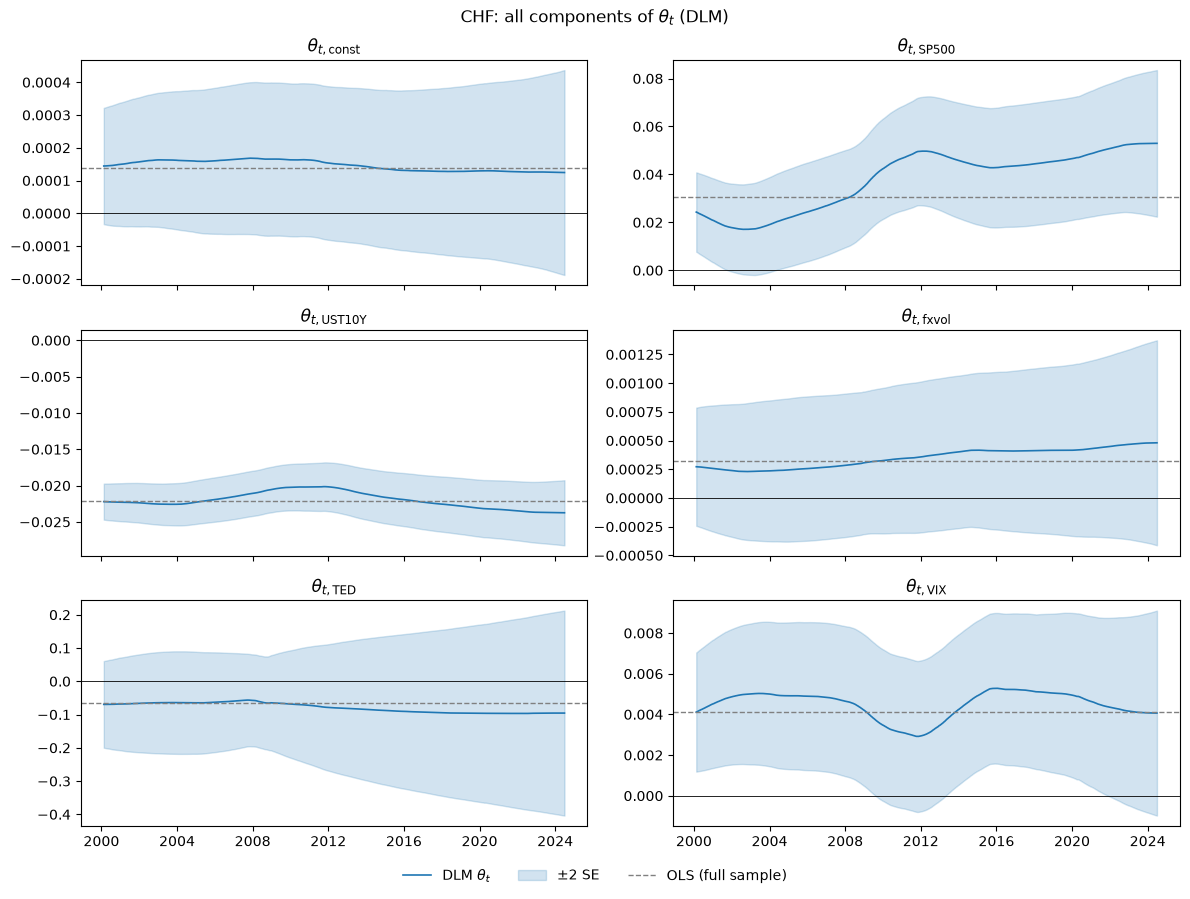

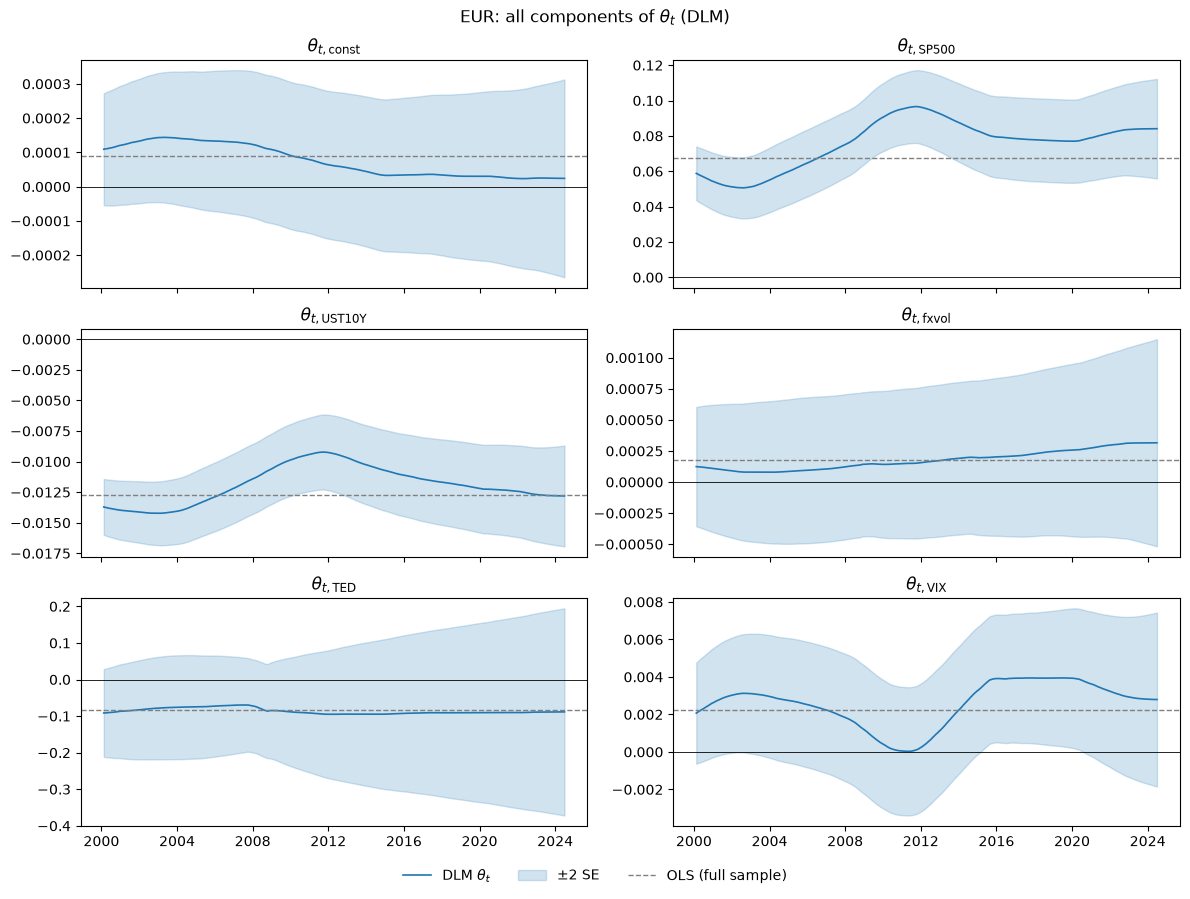

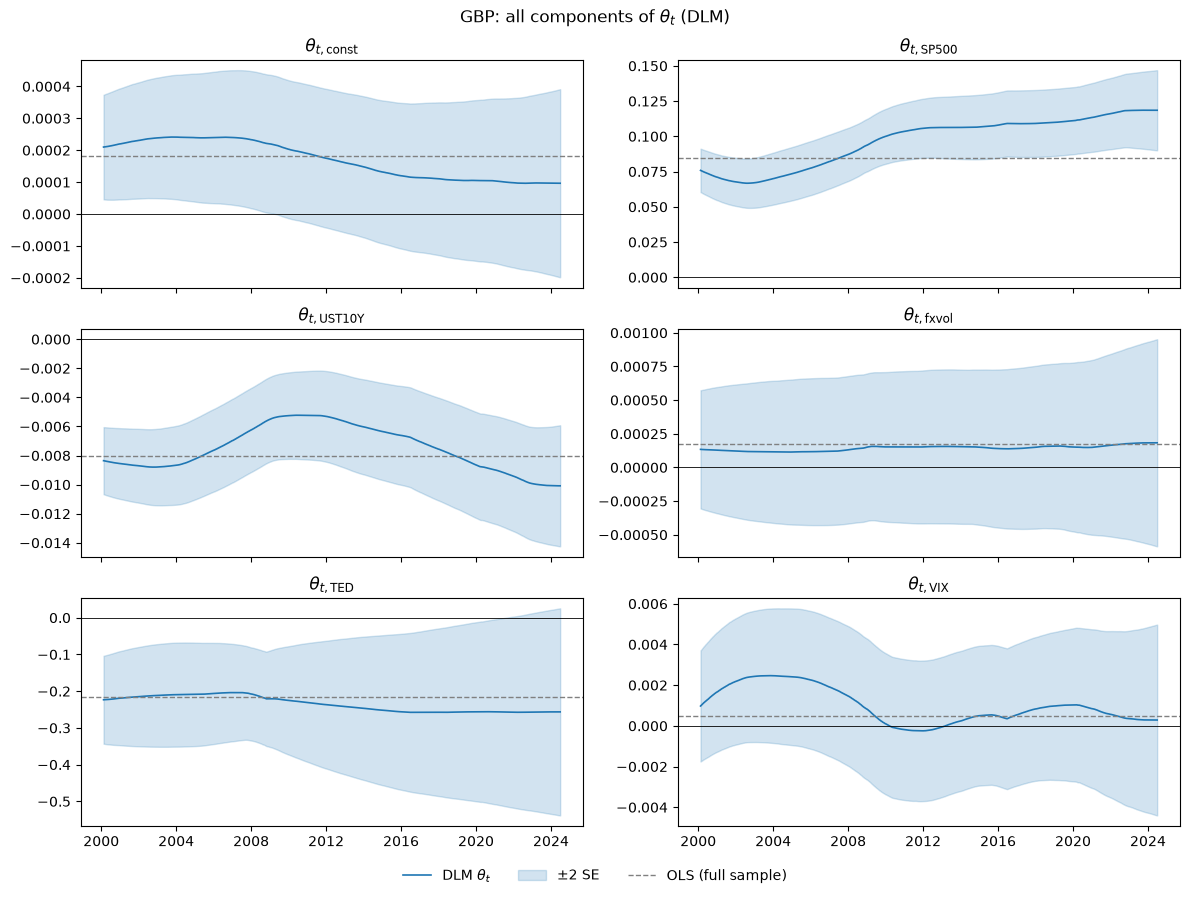

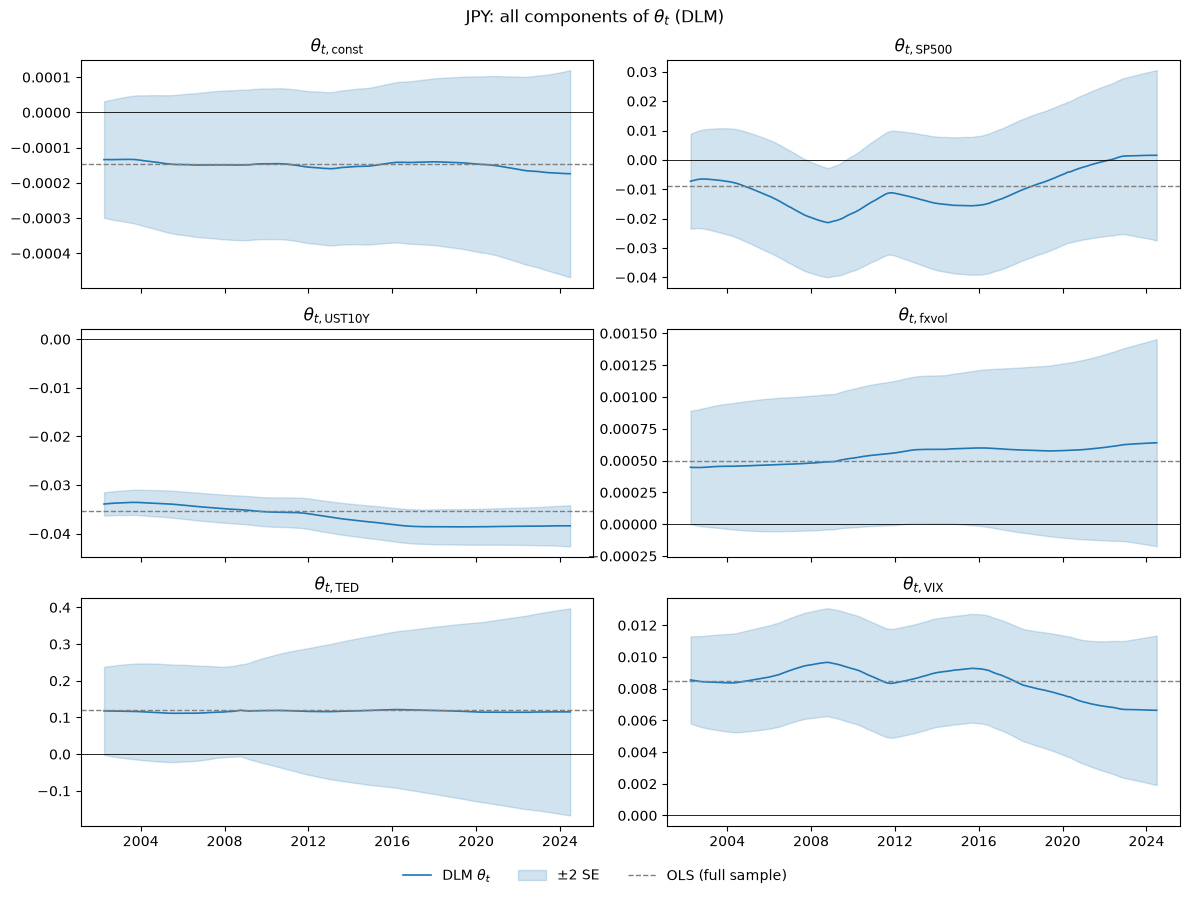

In [5]:
FIG_DIR.mkdir(exist_ok=True)
for cur in CURRENCIES:
    theta, sd, ols = dlm[cur]
    fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
    for ax, term in zip(axes.ravel(), TERMS):
        ax.plot(theta.index, theta[term], color="C0", lw=1.2, label=r"DLM $\theta_t$")
        ax.fill_between(theta.index, theta[term] - 2 * sd[term], theta[term] + 2 * sd[term],
                        color="C0", alpha=0.2, label=r"$\pm$2 SE")
        ax.axhline(ols[TERMS.index(term)], color="grey", ls="--", lw=1, label="OLS (full sample)")
        ax.axhline(0, color="black", lw=0.6)
        ax.set_title(fr"$\theta_{{t,\mathrm{{{term}}}}}$")
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, -0.005))
    fig.suptitle(fr"{cur}: all components of $\theta_t$ (DLM)")
    fig.tight_layout(rect=[0, 0.03, 1, 1])
    fig.savefig(FIG_DIR / f"dlm_{cur}_all.png", dpi=300, bbox_inches="tight")
    plt.show()

## Standardised coefficients with break dates

Each smoothed coefficient expressed as its deviation from the full-sample OLS value in standard-error units, so all six panels share one axis. Points outside the $\pm2$ band are where the coefficient is meaningfully different from its constant value; the Bai-Perron break dates are overlaid (dotted).

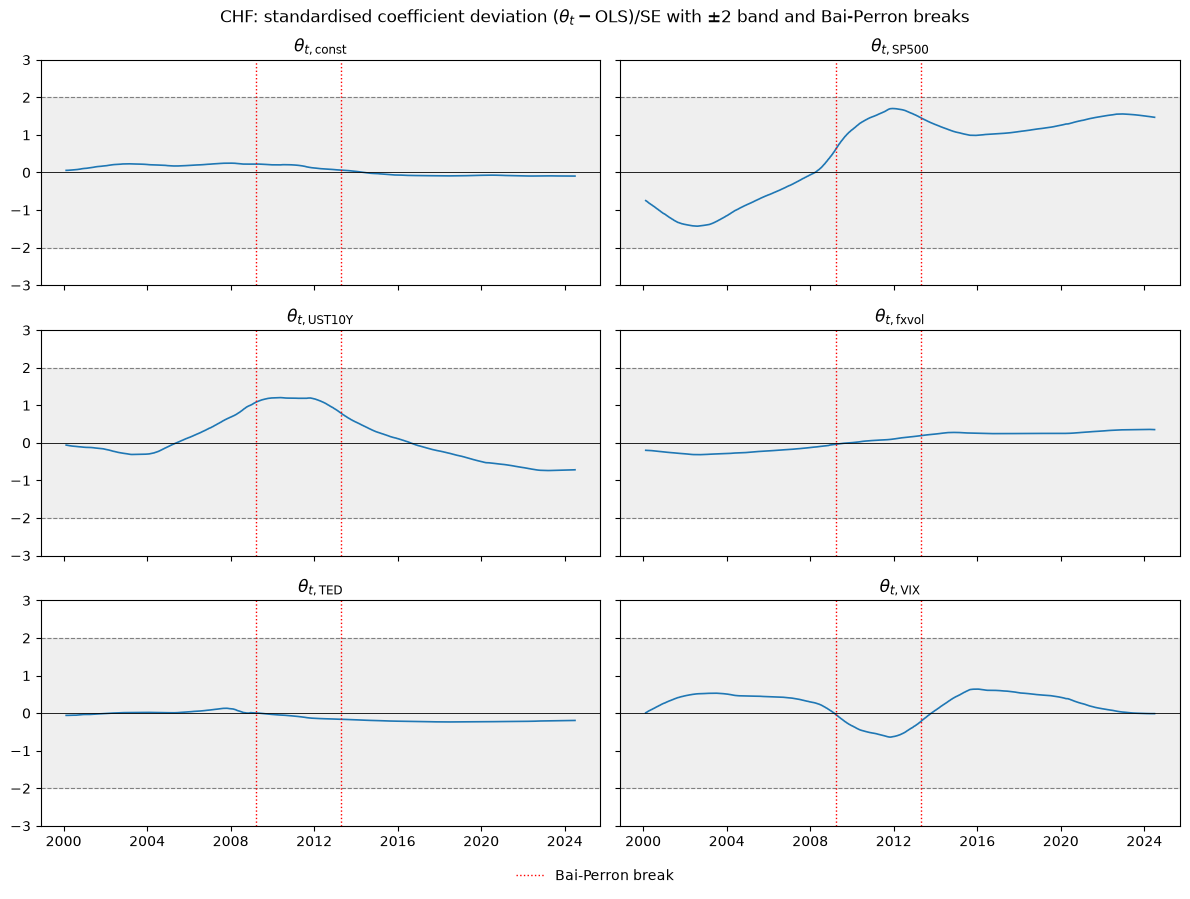

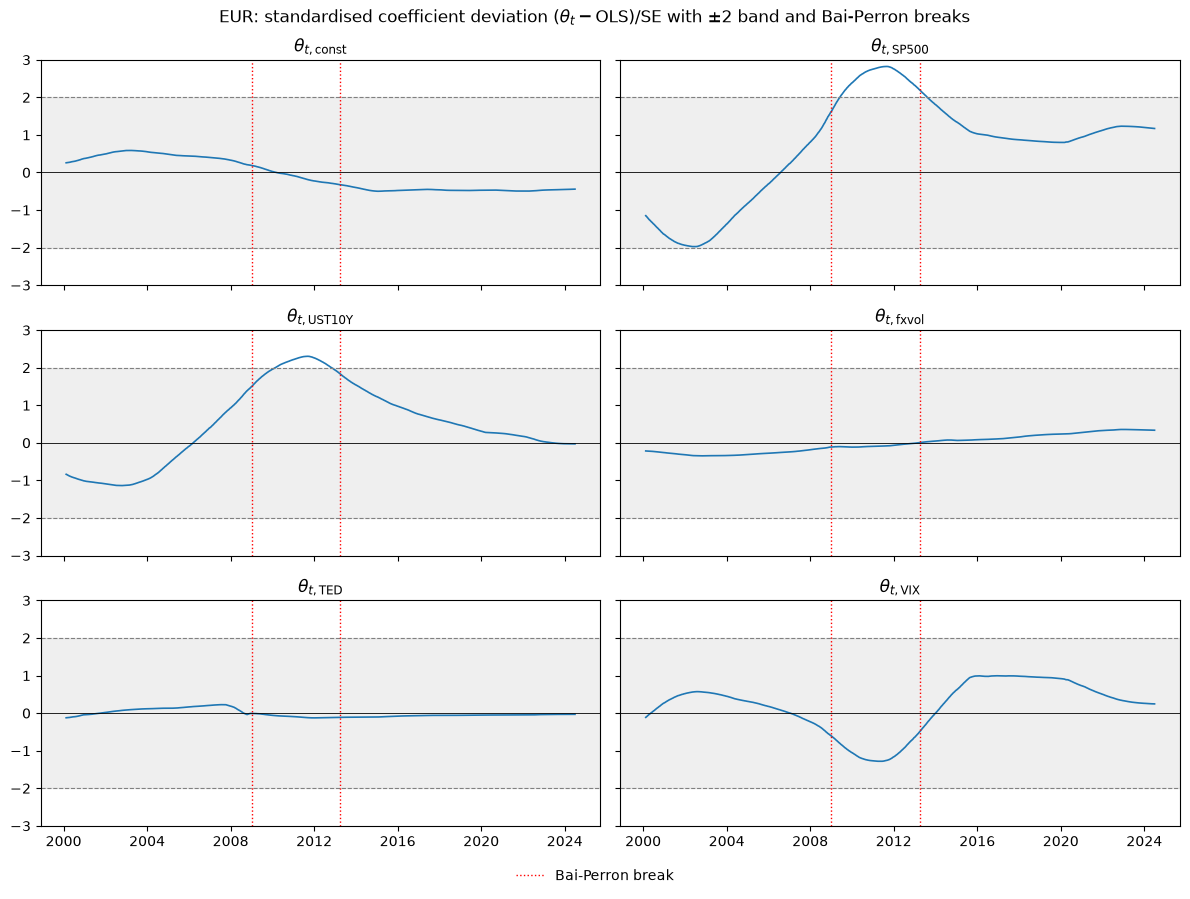

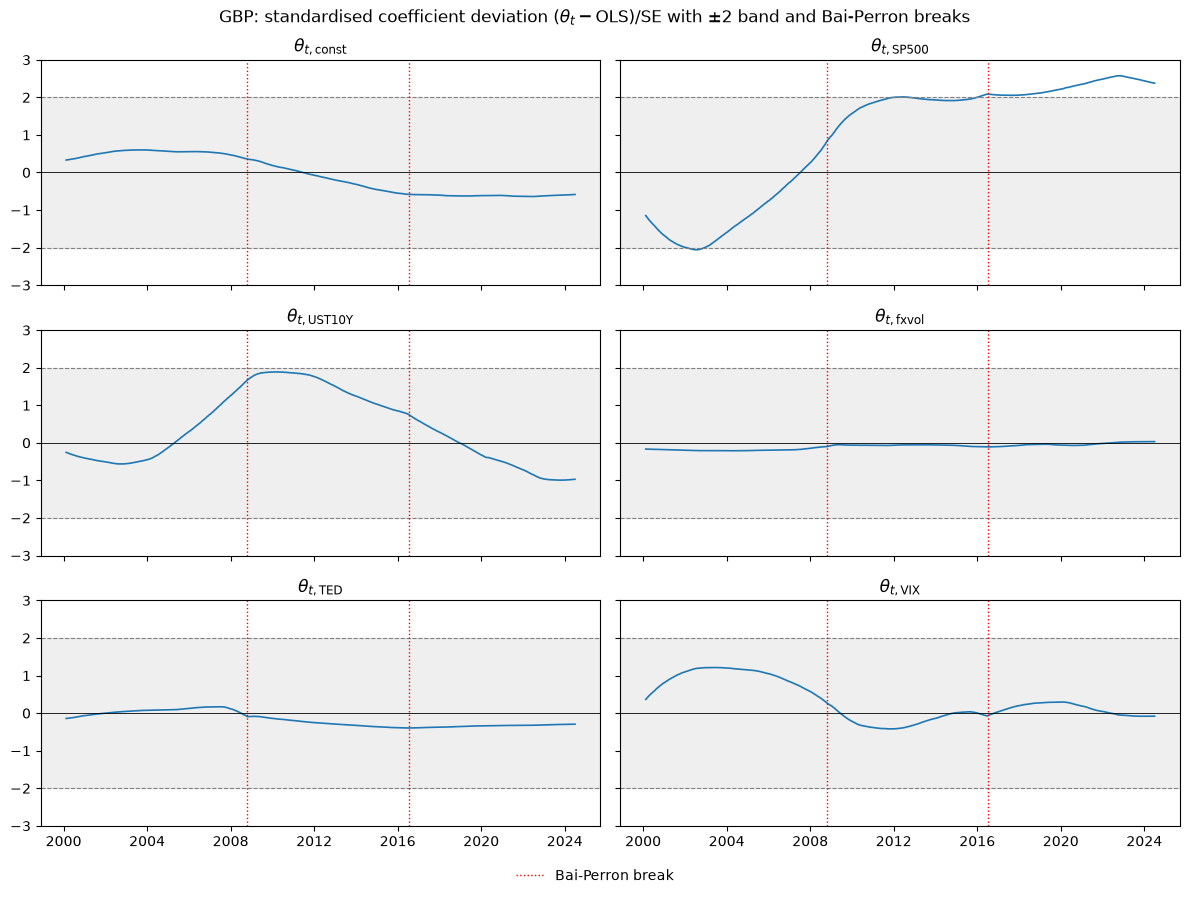

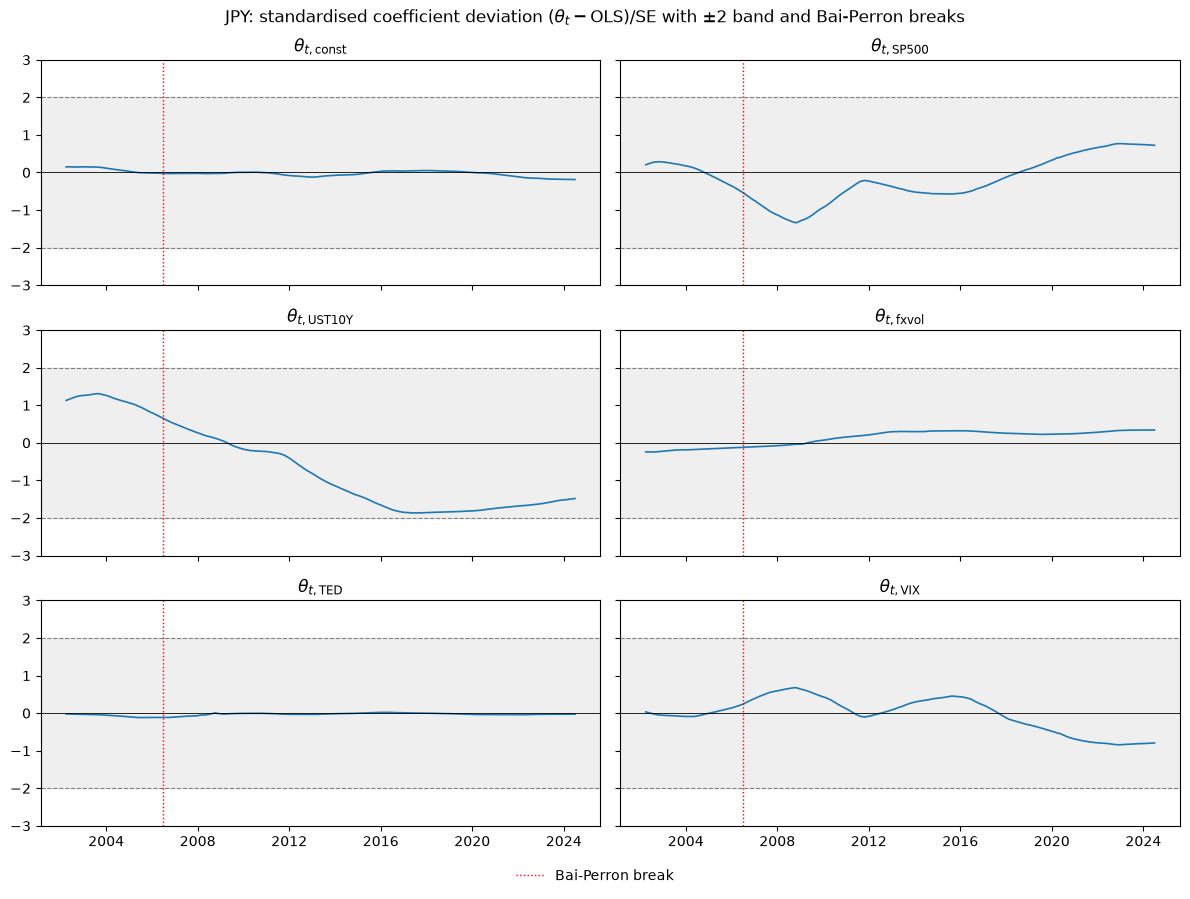

In [6]:
# Standardised view: deviation of each smoothed coefficient from its full-sample
# OLS value, in standard-error units, z_t = (theta_t - OLS)/SE_t. On this scale all
# six panels share one axis, and |z_t| > 2 marks where the coefficient's own 95%
# band excludes the constant OLS estimate -- i.e. meaningful time variation. The
# grey band is the +/-2 "indistinguishable from OLS" zone; Bai-Perron break dates
# are overlaid for direct comparison.
for cur in CURRENCIES:
    theta, sd, ols = dlm[cur]
    z = pd.DataFrame({term: (theta[term] - ols[TERMS.index(term)]) / sd[term]
                      for term in TERMS})
    ymax = min(8.0, max(3.0, float(np.ceil(z.abs().quantile(0.995).max()))))  # floor at 3 so the +/-2 band stays a sub-region with visible headroom
    fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True, sharey=True)
    for ax, term in zip(axes.ravel(), TERMS):
        ax.axhspan(-2, 2, color="grey", alpha=0.12)
        ax.plot(z.index, z[term], color="C0", lw=1.2)
        ax.axhline(0, color="black", lw=0.6)
        ax.axhline(2, color="grey", ls="--", lw=0.8)
        ax.axhline(-2, color="grey", ls="--", lw=0.8)
        for j, d in enumerate(bp.get(cur, [])):
            ax.axvline(d, color="red", ls=":", lw=1,
                       label="Bai-Perron break" if j == 0 else None)
        ax.set_ylim(-ymax, ymax)
        ax.set_title(fr"$\theta_{{t,\mathrm{{{term}}}}}$")
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
                   bbox_to_anchor=(0.5, -0.005))
    fig.suptitle(fr"{cur}: standardised coefficient deviation "
                 fr"$(\theta_t-\mathrm{{OLS}})/\mathrm{{SE}}$ with $\pm2$ band and Bai-Perron breaks")
    fig.tight_layout(rect=[0, 0.03, 1, 1])
    fig.savefig(FIG_DIR / f"dlm_{cur}_std.png", dpi=300, bbox_inches="tight")
    plt.show()

## Joint deviation of the whole coefficient vector

The multivariate counterpart of the per-coefficient view: one line per currency for how far the **entire** coefficient vector sits from its constant OLS value, measured by the Mahalanobis distance $D_t = (\theta_t-\mathrm{OLS})^\top C_t^{-1}(\theta_t-\mathrm{OLS})$ with $C_t$ the smoothed state covariance. The dashed line is the 95% quantile of a $\chi^2_6$. I use it as a yardstick, not as a test: the OLS value is itself estimated, the filter starts from it, and the line is crossed or not depending on $\lambda$ (notebook 05). Each currency's break dates are overlaid in its own colour.

CHF: max D_t =   8.6 on 2011-11-01, days above the line: 0
EUR: max D_t =  27.2 on 2011-07-21, days above the line: 961
GBP: max D_t =  12.0 on 2011-10-03, days above the line: 0
JPY: max D_t =   5.1 on 2022-11-10, days above the line: 0


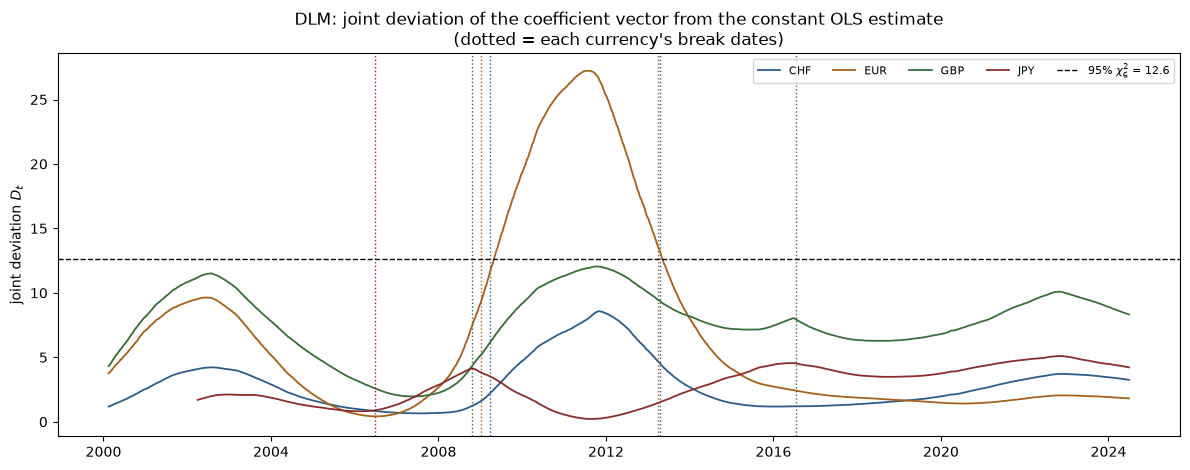

In [7]:
from scipy.stats import chi2

COLOR = {"CHF": "#2f5d8a", "EUR": "#a6611a", "GBP": "#3b6e3b", "JPY": "#8c2d2d"}
threshold = chi2.ppf(0.95, len(TERMS))

fig, ax = plt.subplots(figsize=(12, 4.8))
for cur in CURRENCIES:
    theta_df, _, ols_params = dlm[cur]
    D = pd.Series(sh.joint_deviation(fits[cur], ols_params), index=theta_df.index)
    ax.plot(D.index, D, color=COLOR[cur], lw=1.3, label=cur)
    for d in bp.get(cur, []):
        ax.axvline(d, color=COLOR[cur], ls=":", lw=1)
    print(f"{cur}: max D_t = {D.max():5.1f} on {D.idxmax().date()}, "
          f"days above the line: {int((D > threshold).sum())}")
ax.axhline(threshold, color="black", ls="--", lw=1,
           label=fr"95% $\chi^2_6$ = {threshold:.1f}")
ax.set_ylabel(r"joint deviation $D_t$")
ax.legend(ncol=5, fontsize=8, loc="upper right")
ax.set_title("DLM: joint deviation of the coefficient vector from the constant OLS estimate\n"
             "(dotted = each currency's break dates)")
fig.tight_layout()
fig.savefig(FIG_DIR / "dlm_joint_deviation.png", dpi=300, bbox_inches="tight")
plt.show()

## Persist

In [8]:
paths = pd.concat({cur: dlm[cur][0] for cur in CURRENCIES}, axis=1)
paths.columns.names = ["currency", "coefficient"]
out = DATA_DIR / "dlm_coefficients.csv"
paths.to_csv(out)
print(f"Saved smoothed state theta_t -> {out.relative_to(sh.ROOT)}")
print("Saved figures -> figures/dlm_*.png")

Saved smoothed state theta_t -> data/dlm_coefficients.csv
Saved figures -> figures/dlm_*.png
